# CS688 Homework 2

## 1. Tasks

- Collect at least 20 English titles that each contain at least one chosen search keyword.
- Score each title with a classical sentiment lexicon (AFINN).
- Score each title with a pretrained Hugging Face Transformer classifier (DistilBERT).
- Manually assign exactly one one-word theme per title.
- Export an Excel file with **exactly four columns**: Text, Classical Sentiment Score, Modern Sentiment Score, Theme.

## 2. Setup

Run:

```
pip3 install pandas openpyxl afinn transformers torch matplotlib requests beautifulsoup4
```


In [1]:
import io
import re
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from afinn import Afinn
from transformers import pipeline
from IPython.display import display, Image


/Users/chrisdavis/personal/cs688_old/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Data collection

**Topic.** AI, investment, and compute — the same keyword set used in Homework 1.

**Search keywords.** `ai`, `invest`, and `compute`. A title only needed to contain **one** of these (including close forms such as *AI*, *investment*, or *compute*).

**Source.** Bing News, using the Homework 1 scraper (`requests` + BeautifulSoup). Collected on 20 September 2026.

**Approach.** I reused the HW1 Bing News scraper to download 50 headlines, saved them to `search_results_titles.csv`, then **manually selected 20** distinct titles for this assignment. Only the title text is scored, not the article body. Theme labels were assigned by hand afterward, not by the scraper.

**Sample size.** 20 titles. Several contain more than one keyword. Each title is tagged with the keyword that best matches why it was collected.


In [2]:
# Reused from Homework 1: Bing News scraper for ("ai", "invest", "compute").
# If the CSV already exists, load it so later cells stay reproducible.

keywords = ["ai", "invest", "compute"]
query = " ".join(keywords)
output_csv = Path("search_results_titles.csv")
results_needed = 50
page_size = 10
base_url = "https://www.bing.com/news/search"
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    )
}

if output_csv.exists():
    scraped_titles = [line.strip() for line in output_csv.read_text().splitlines() if line.strip()]
    print(f"Loaded {len(scraped_titles)} titles from {output_csv}")
else:
    scraped_titles = []
    offset = 0
    while len(scraped_titles) < results_needed and offset < 80:
        params = {"q": query, "first": offset}
        response = requests.get(base_url, params=params, headers=headers, timeout=15)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, features="html.parser")
        page_titles = [tag.get_text(strip=True) for tag in soup.select("a.title") if tag.get_text(strip=True)]
        for title in page_titles:
            if title not in scraped_titles:
                scraped_titles.append(title)
            if len(scraped_titles) >= results_needed:
                break
        offset += page_size
        time.sleep(1)
    scraped_titles = scraped_titles[:results_needed]
    output_csv.write_text("\n".join(scraped_titles) + "\n")
    print(f"Wrote {len(scraped_titles)} titles to {output_csv}")

print(pd.Series(scraped_titles).head(10).to_string())


Loaded 50 titles from search_results_titles.csv
0    Bridgewater's Greg Jensen wants AI compute gia...
1    SK Hynix Launches Silicon Valley Venture Arm T...
2    Fastly Highlights Accelerating Growth, Record ...
3    AI compute crunch pays off for CoreWeave as ca...
4    Follow Anthropic's Actions, Not It's Rhetoric:...
5    Nebius Group (NBIS) Raises AI Cloud Prices As ...
6    The AI compute gap: Enterprises are buying inf...
7    Nebius Becomes Palantir’s Secret Weapon as AI ...
8    OpenAI Taps Firmus for Two Malaysia AI Data Ce...
9    Piper Sandler says AI is causing 'insatiable d...


In [3]:
# 20 titles manually selected from the HW1 Bing News scrape (20 September 2026).
# Themes were assigned by reading each title. Provenance stays in this notebook,
# not in the Excel file.
records = [
    {
        "text": "Bridgewater's Greg Jensen wants AI compute giants treated like too-big-to-fail banks",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Regulation",
    },
    {
        "text": "SK Hynix Launches Silicon Valley Venture Arm To Invest Across AI Computing, Data Centers And Optical Interconnects",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Expansion",
    },
    {
        "text": "Fastly Highlights Accelerating Growth, Record Margins and AI-Driven Compute Demand",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Demand",
    },
    {
        "text": "AI compute crunch pays off for CoreWeave as capacity fetches higher prices",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Pricing",
    },
    {
        "text": "Follow Anthropic's Actions, Not It's Rhetoric: 5 AI Stocks to Benefit From Anthropic's $517 Billion in Compute Commitments",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Rhetoric",
    },
    {
        "text": "Nebius Group (NBIS) Raises AI Cloud Prices As Compute Demand Tests Customer Costs",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Pricing",
    },
    {
        "text": "The AI compute gap: Enterprises are buying infrastructure faster than they can measure what it costs",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Measurement",
    },
    {
        "text": "OpenAI Taps Firmus for Two Malaysia AI Data Centers as APAC Compute Race Accelerates",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Expansion",
    },
    {
        "text": "RUM's $13.7B compute win contradicts AI safety concerns",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Safety",
    },
    {
        "text": "Jane Street bets $19B on AI compute: Crusoe closes $3B round as finance eclipses labs",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Finance",
    },
    {
        "text": "Finding where the power is to fuel AI compute",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Energy",
    },
    {
        "text": "Blackstone plans to invest tens of billions in Google AI chips",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Chips",
    },
    {
        "text": "Alibaba Quarterly Profit Drops 75% as AI Investment Spending Grows",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Profit",
    },
    {
        "text": "If an AI bubble burst is coming, history says this 1 investing move is crucial right now",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Bubble",
    },
    {
        "text": "Australia Lags Behind UK and Canada on Sovereign AI Capability as Funding and Compute Gaps Risk Foreign Reliance",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Sovereignty",
    },
    {
        "text": "Nvidia to Invest $1.5 Billion in SB Energy, Supply AI Compute for Ohio Data Center",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Energy",
    },
    {
        "text": "SpaceX Wants to Deploy Millions of AI Compute Satellites in Space. Here's How It Plans to Get There.",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Satellites",
    },
    {
        "text": "How Do You Invest In The AI Value Chain?",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Strategy",
    },
    {
        "text": "Anthropic secures $517B in AI compute deals with Amazon, Google over 10 years",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "compute",
        "theme": "Deals",
    },
    {
        "text": "US-Europe Investment Gap Widens Due to AI Surge",
        "publisher": "Bing News",
        "date": "2026-09-20",
        "matched_keyword": "invest",
        "theme": "Geography",
    },
]

raw_df = pd.DataFrame(records)
print(f"Selected titles: {len(raw_df)}")
print(raw_df["matched_keyword"].value_counts().to_string())
print()
display(raw_df[["text", "publisher", "date", "matched_keyword", "theme"]])


Selected titles: 20
matched_keyword
compute    13
invest      7



,text,publisher,date,matched_keyword,theme
0,Bridgewater's Greg Jensen wants AI compute gia...,Bing News,2026-09-20,compute,Regulation
1,SK Hynix Launches Silicon Valley Venture Arm T...,Bing News,2026-09-20,invest,Expansion
2,"Fastly Highlights Accelerating Growth, Record ...",Bing News,2026-09-20,compute,Demand
3,AI compute crunch pays off for CoreWeave as ca...,Bing News,2026-09-20,compute,Pricing
4,"Follow Anthropic's Actions, Not It's Rhetoric:...",Bing News,2026-09-20,compute,Rhetoric
5,Nebius Group (NBIS) Raises AI Cloud Prices As ...,Bing News,2026-09-20,compute,Pricing
6,The AI compute gap: Enterprises are buying inf...,Bing News,2026-09-20,compute,Measurement
7,OpenAI Taps Firmus for Two Malaysia AI Data Ce...,Bing News,2026-09-20,compute,Expansion
8,RUM's $13.7B compute win contradicts AI safety...,Bing News,2026-09-20,compute,Safety
9,Jane Street bets $19B on AI compute: Crusoe cl...,Bing News,2026-09-20,compute,Finance


## 4. Manual theme analysis

Themes were assigned **by reading each title**, not by an algorithm. I did not use keyword extraction, topic modeling, clustering, TextRank, RAKE, YAKE, or an LLM to choose the theme values.

Rules I followed:

- Exactly **one word** per title.
- The theme describes the *meaning* of the title, not the search keyword. So I did not use `AI`, `Invest`, or `Compute` as themes.
- Repeated themes are allowed. `Pricing` and `Energy` each appear twice because two headlines really share that meaning.

This is qualitative human annotation and is intentionally subjective. Another reader might tag the Alibaba headline as `Spending` instead of `Profit`, or the Bridgewater headline as `Banks` instead of `Regulation`.


## 5. Classical sentiment: AFINN

AFINN is a unigram lexicon. Each known word has a fixed integer score, usually from -5 (very negative) to +5 (very positive). The title score is the **sum** of the word scores. Unknown words contribute 0.

That makes AFINN transparent: I can list which words produced the score. It also makes AFINN weak on context, negation, idioms, sarcasm, and implicit sentiment, because it mostly scores words in isolation.

I treat AFINN `> 0` as positive, `< 0` as negative, and `= 0` as neutral. A zero score often means the title is factual, or that AFINN simply did not recognize the loaded words.


In [4]:
afinn = Afinn()


def afinn_words(text: str) -> str:
    # Show the lexicon hits so the AFINN score is inspectable.
    tokens = re.findall(r"[A-Za-z']+", text.lower())
    hits = [f"{tok} ({afinn.score(tok):+g})" for tok in tokens if afinn.score(tok) != 0]
    return ", ".join(hits) if hits else "(no lexicon hits)"


raw_df["classical_score"] = raw_df["text"].map(afinn.score)
raw_df["classical_words"] = raw_df["text"].map(afinn_words)
raw_df["classical_label"] = raw_df["classical_score"].map(
    lambda s: "positive" if s > 0 else "negative" if s < 0 else "neutral"
)

display(raw_df[["text", "classical_score", "classical_label", "classical_words"]])


,text,classical_score,classical_label,classical_words
0,Bridgewater's Greg Jensen wants AI compute gia...,1.0,positive,"like (+2), big (+1), fail (-2)"
1,SK Hynix Launches Silicon Valley Venture Arm T...,0.0,neutral,(no lexicon hits)
2,"Fastly Highlights Accelerating Growth, Record ...",1.0,positive,"growth (+2), demand (-1)"
3,AI compute crunch pays off for CoreWeave as ca...,0.0,neutral,(no lexicon hits)
4,"Follow Anthropic's Actions, Not It's Rhetoric:...",2.0,positive,benefit (+2)
5,Nebius Group (NBIS) Raises AI Cloud Prices As ...,-1.0,negative,demand (-1)
6,The AI compute gap: Enterprises are buying inf...,0.0,neutral,(no lexicon hits)
7,OpenAI Taps Firmus for Two Malaysia AI Data Ce...,0.0,neutral,(no lexicon hits)
8,RUM's $13.7B compute win contradicts AI safety...,5.0,positive,"win (+4), safety (+1)"
9,Jane Street bets $19B on AI compute: Crusoe cl...,0.0,neutral,(no lexicon hits)


## 6. Modern sentiment: DistilBERT

I used Hugging Face `distilbert-base-uncased-finetuned-sst-2-english`. It is a compact Transformer sentiment classifier pretrained on the Stanford Sentiment Treebank (movie-review phrases). It outputs a label (`POSITIVE` or `NEGATIVE`) and a confidence probability.

This model uses contextual embeddings, so it can pick up phrases such as *hits a wall* that AFINN cannot. It is **not** automatically correct:

- SST-2 is a **binary** task. There is no `NEUTRAL` class, so factual headlines are forced into positive or negative.
- Short technical titles are a domain shift from movie-review phrases.
- High confidence is not the same thing as being right.

The modern score is stored as `LABEL (confidence)`, for example `NEGATIVE (0.996)`.


In [5]:
sentiment_clf = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
)

modern_rows = []
for title in raw_df["text"]:
    result = sentiment_clf(title)[0]
    modern_rows.append(
        {
            "modern_label": result["label"],
            "modern_confidence": round(float(result["score"]), 3),
            "modern_score": f"{result['label']} ({result['score']:.3f})",
        }
    )

modern_df = pd.DataFrame(modern_rows)
raw_df = pd.concat([raw_df.reset_index(drop=True), modern_df], axis=1)
display(raw_df[["text", "classical_score", "modern_score", "theme"]])


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 9410.96it/s]

,text,classical_score,modern_score,theme
0,Bridgewater's Greg Jensen wants AI compute gia...,1.0,NEGATIVE (0.999),Regulation
1,SK Hynix Launches Silicon Valley Venture Arm T...,0.0,POSITIVE (0.997),Expansion
2,"Fastly Highlights Accelerating Growth, Record ...",1.0,POSITIVE (1.000),Demand
3,AI compute crunch pays off for CoreWeave as ca...,0.0,NEGATIVE (0.906),Pricing
4,"Follow Anthropic's Actions, Not It's Rhetoric:...",2.0,NEGATIVE (0.987),Rhetoric
5,Nebius Group (NBIS) Raises AI Cloud Prices As ...,-1.0,NEGATIVE (0.948),Pricing
6,The AI compute gap: Enterprises are buying inf...,0.0,NEGATIVE (0.999),Measurement
7,OpenAI Taps Firmus for Two Malaysia AI Data Ce...,0.0,NEGATIVE (0.776),Expansion
8,RUM's $13.7B compute win contradicts AI safety...,5.0,NEGATIVE (0.989),Safety
9,Jane Street bets $19B on AI compute: Crusoe cl...,0.0,NEGATIVE (0.995),Finance


## 7. Excel deliverable

The Excel file has exactly the four required columns. Provenance, AFINN word hits, and DistilBERT confidence as a separate numeric field stay in this notebook only.


In [6]:
excel_df = pd.DataFrame(
    {
        "Text": raw_df["text"],
        "Classical Sentiment Score": raw_df["classical_score"],
        "Modern Sentiment Score": raw_df["modern_score"],
        "Theme": raw_df["theme"],
    }
)

excel_path = "cs688_hw2_davis_chris.xlsx"
excel_df.to_excel(excel_path, index=False)
print(f"Wrote {excel_path} with shape {excel_df.shape}")
print("Columns:", list(excel_df.columns))
display(excel_df)


Wrote cs688_hw2_davis_chris.xlsx with shape (20, 4)
Columns: ['Text', 'Classical Sentiment Score', 'Modern Sentiment Score', 'Theme']


,Text,Classical Sentiment Score,Modern Sentiment Score,Theme
0,Bridgewater's Greg Jensen wants AI compute gia...,1.0,NEGATIVE (0.999),Regulation
1,SK Hynix Launches Silicon Valley Venture Arm T...,0.0,POSITIVE (0.997),Expansion
2,"Fastly Highlights Accelerating Growth, Record ...",1.0,POSITIVE (1.000),Demand
3,AI compute crunch pays off for CoreWeave as ca...,0.0,NEGATIVE (0.906),Pricing
4,"Follow Anthropic's Actions, Not It's Rhetoric:...",2.0,NEGATIVE (0.987),Rhetoric
5,Nebius Group (NBIS) Raises AI Cloud Prices As ...,-1.0,NEGATIVE (0.948),Pricing
6,The AI compute gap: Enterprises are buying inf...,0.0,NEGATIVE (0.999),Measurement
7,OpenAI Taps Firmus for Two Malaysia AI Data Ce...,0.0,NEGATIVE (0.776),Expansion
8,RUM's $13.7B compute win contradicts AI safety...,5.0,NEGATIVE (0.989),Safety
9,Jane Street bets $19B on AI compute: Crusoe cl...,0.0,NEGATIVE (0.995),Finance


## 8. Comparison of the two methods

AFINN can be neutral. DistilBERT cannot. I therefore look at two things: (1) whether the polarities agree when AFINN is non-zero, and (2) cases where AFINN is 0 but DistilBERT still commits to a label.


In [7]:
def polarity_agreement(row):
    if row["classical_label"] == "neutral":
        return "AFINN neutral / DistilBERT forced polarity"
    if row["classical_label"] == "positive" and row["modern_label"] == "POSITIVE":
        return "agree (positive)"
    if row["classical_label"] == "negative" and row["modern_label"] == "NEGATIVE":
        return "agree (negative)"
    return "disagree"


raw_df["comparison"] = raw_df.apply(polarity_agreement, axis=1)
print(raw_df["comparison"].value_counts().to_string())
print()
print("AFINN label counts:")
print(raw_df["classical_label"].value_counts().to_string())
print()
print("DistilBERT label counts:")
print(raw_df["modern_label"].value_counts().to_string())

disagree_df = raw_df[raw_df["comparison"].str.contains("disagree|neutral")][
    ["text", "classical_score", "classical_words", "modern_score", "theme", "comparison"]
]
display(disagree_df)


comparison
AFINN neutral / DistilBERT forced polarity    12
disagree                                       5
agree (negative)                               2
agree (positive)                               1

AFINN label counts:
classical_label
neutral     12
positive     6
negative     2

DistilBERT label counts:
modern_label
NEGATIVE    17
POSITIVE     3


,text,classical_score,classical_words,modern_score,theme,comparison
0,Bridgewater's Greg Jensen wants AI compute gia...,1.0,"like (+2), big (+1), fail (-2)",NEGATIVE (0.999),Regulation,disagree
1,SK Hynix Launches Silicon Valley Venture Arm T...,0.0,(no lexicon hits),POSITIVE (0.997),Expansion,AFINN neutral / DistilBERT forced polarity
3,AI compute crunch pays off for CoreWeave as ca...,0.0,(no lexicon hits),NEGATIVE (0.906),Pricing,AFINN neutral / DistilBERT forced polarity
4,"Follow Anthropic's Actions, Not It's Rhetoric:...",2.0,benefit (+2),NEGATIVE (0.987),Rhetoric,disagree
6,The AI compute gap: Enterprises are buying inf...,0.0,(no lexicon hits),NEGATIVE (0.999),Measurement,AFINN neutral / DistilBERT forced polarity
7,OpenAI Taps Firmus for Two Malaysia AI Data Ce...,0.0,(no lexicon hits),NEGATIVE (0.776),Expansion,AFINN neutral / DistilBERT forced polarity
8,RUM's $13.7B compute win contradicts AI safety...,5.0,"win (+4), safety (+1)",NEGATIVE (0.989),Safety,disagree
9,Jane Street bets $19B on AI compute: Crusoe cl...,0.0,(no lexicon hits),NEGATIVE (0.995),Finance,AFINN neutral / DistilBERT forced polarity
10,Finding where the power is to fuel AI compute,0.0,(no lexicon hits),NEGATIVE (0.997),Energy,AFINN neutral / DistilBERT forced polarity
11,Blackstone plans to invest tens of billions in...,0.0,(no lexicon hits),NEGATIVE (0.949),Chips,AFINN neutral / DistilBERT forced polarity


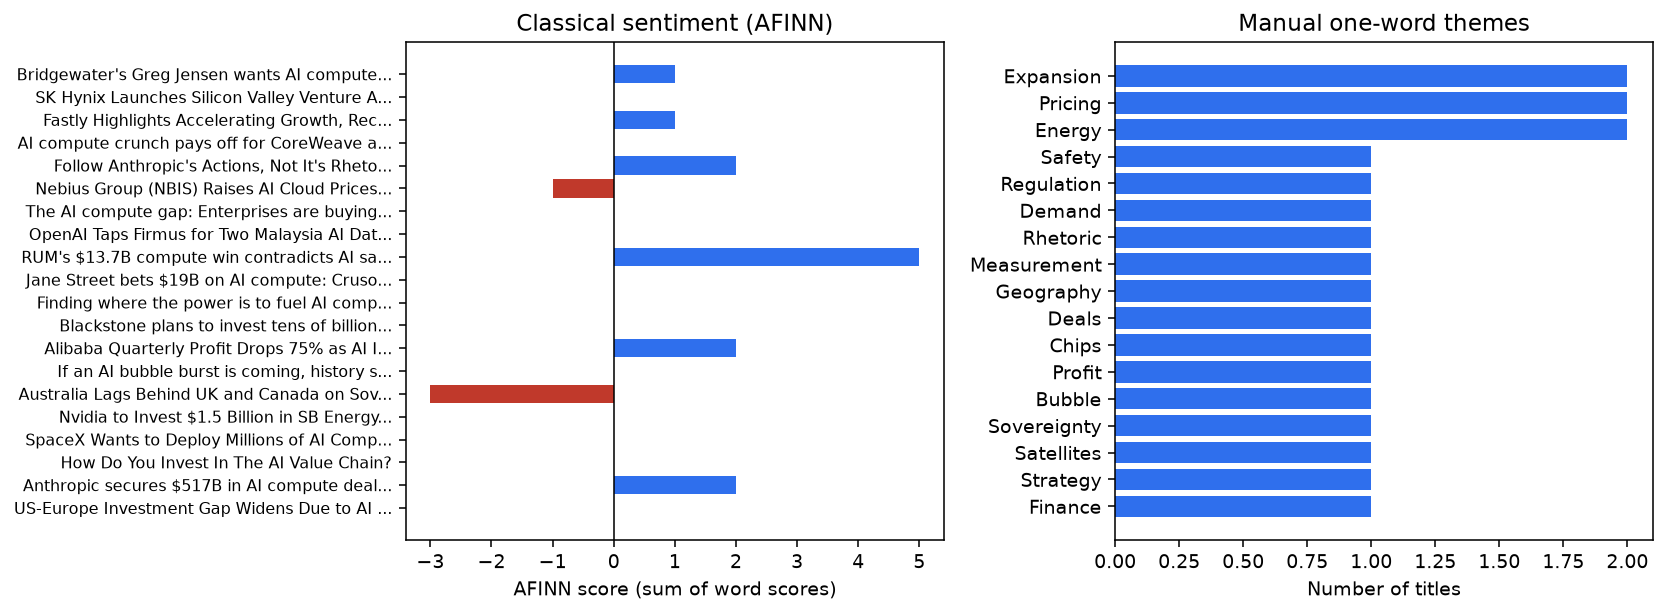

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colors = ["#2f6fed" if s > 0 else "#c0392b" if s < 0 else "#7f8c8d" for s in raw_df["classical_score"]]
axes[0].barh(range(len(raw_df)), raw_df["classical_score"], color=colors)
axes[0].set_yticks(range(len(raw_df)))
axes[0].set_yticklabels([t[:42] + ("..." if len(t) > 42 else "") for t in raw_df["text"]], fontsize=8)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()
axes[0].set_xlabel("AFINN score (sum of word scores)")
axes[0].set_title("Classical sentiment (AFINN)")

theme_counts = raw_df["theme"].value_counts().sort_values()
axes[1].barh(theme_counts.index, theme_counts.values, color="#2f6fed")
axes[1].set_xlabel("Number of titles")
axes[1].set_title("Manual one-word themes")

plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=140, bbox_inches="tight")
plt.close(fig)
display(Image(data=buf.getvalue()))


## 9. Findings

### 9.1 Many titles are factual, not opinionated

News headlines are often objective statements (*Blackstone plans to invest tens of billions in Google AI chips*, *Finding where the power is to fuel AI compute*). AFINN scores several of these as **0** because no lexicon word fired. DistilBERT still returns `POSITIVE` or `NEGATIVE`, sometimes with high confidence, because SST-2 has no neutral class. That is a model limitation, not evidence that the headline is actually opinionated.

### 9.2 AFINN is transparent but misses context

- **Too-big-to-fail banks.** AFINN = +1 from *like (+2)*, *big (+1)*, and *fail (-2)*. DistilBERT is `NEGATIVE (0.999)`. DistilBERT better captures the regulatory warning; AFINN nets out the idiom into a weakly positive score.
- **Compute win contradicts safety.** AFINN = +5 from *win (+4)* and *safety (+1)*. DistilBERT is `NEGATIVE (0.989)`. AFINN misses *contradicts* and treats *safety* as good. The headline is skeptical.
- **Alibaba profit drops 75%.** AFINN = +2 from *profit*. DistilBERT is `NEGATIVE (0.997)`. AFINN scores the noun and ignores *drops*.
- **Follow actions, not rhetoric.** AFINN = +2 from *benefit*. DistilBERT is `NEGATIVE (0.987)`. The title is mixed/skeptical; AFINN only sees the positive stock-picking frame.
- **Australia lags / compute gaps.** AFINN = -3 from *lags (-2)*, *capability (+1)*, and *risk (-2)*. DistilBERT is `NEGATIVE (0.976)`. Both agree.
- **AI bubble burst.** AFINN = 0. DistilBERT is `POSITIVE (0.992)`. DistilBERT is overconfident here: a bubble warning is not a positive headline.
- **Anthropic secures $517B.** AFINN = +2 from *secures*. DistilBERT is `NEGATIVE (0.981)`. This is a factual deal headline; DistilBERT's polarity is not automatically correct.
- **How do you invest in the AI value chain?** AFINN = 0. DistilBERT is `NEGATIVE (0.998)`. A question is closer to neutral than negative.

### 9.3 DistilBERT is not ground truth

The Transformer uses context and sometimes wins (*profit drops*, *contradicts safety*, *too-big-to-fail*). It also over-polarizes factual or interrogative titles and cannot say *neutral*. I treat the two scores as complementary evidence, not as a winner and a loser.

### 9.4 Themes

The 20 titles are not one topic. Manual themes split into market behavior (`Pricing`, `Demand`, `Bubble`, `Profit`), infrastructure (`Energy`, `Satellites`, `Chips`, `Deals`), and politics/risk (`Regulation`, `Safety`, `Sovereignty`, `Geography`). None of those labels repeats a search keyword.


## 10. Summary

| Item | Choice |
|---|---|
| Keywords | ai, invest, compute (same set as Homework 1) |
| Source | Bing News titles via the HW1 scraper, collected 20 September 2026 |
| Sample | 50 scraped headlines; 20 selected for scoring |
| Classical method | AFINN unigram lexicon (sum of word scores) |
| Modern method | `distilbert-base-uncased-finetuned-sst-2-english` (label + confidence) |
| Themes | One manually assigned word per title |
| Deliverable | `cs688_hw2_davis_chris.xlsx` (4 columns) |

**Video.** The original handout also asks for a short screen-recorded walkthrough of this notebook and the Excel file. I will record that separately unless the course site drops the requirement.
